In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn gradio joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import zipfile
import joblib
import gradio as gr

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    average_precision_score
)

print("FLOODCAST libraries imported successfully!")

FLOODCAST libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving CAMELS_IND_All_Catchments.zip to CAMELS_IND_All_Catchments.zip


In [20]:
import zipfile
import os

zip_file = next(
    (name for name in uploaded if name.endswith(".zip")),
    None
)

if zip_file is None:
    print("ZIP file not found. Please check your upload.")
else:
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall("/content/CAMELS_IND")

    print("Dataset extracted successfully!")
    print(os.listdir("/content/CAMELS_IND"))

Dataset extracted successfully!
['attributes_txt', 'change_logs_and_disclaimer.txt', 'filter_catchment.py', 'catchment_mean_forcings', 'streamflow_timeseries', 'CAMELS_IND_Data_Description.pdf', 'shapefiles_catchment', 'attributes_csv']


In [21]:
base_path = "/content/CAMELS_IND"

print("CATCHMENT MEAN FORCINGS:")
print(os.listdir(os.path.join(base_path, "catchment_mean_forcings"))[:10])

print("\nSTREAMFLOW TIMESERIES:")
print(os.listdir(os.path.join(base_path, "streamflow_timeseries"))[:10])

print("\nATTRIBUTE CSV FILES:")
print(os.listdir(os.path.join(base_path, "attributes_csv"))[:10])

CATCHMENT MEAN FORCINGS:
['08007.csv', '08018.csv', '03035.csv', '15017.csv', '16012.csv', '03074.csv', '13023.csv', '08006.csv', '09002.csv', '08025.csv']

STREAMFLOW TIMESERIES:
['lstm_pred_streamflow.csv', 'streamflow_observed.csv']

ATTRIBUTE CSV FILES:
['camels_ind_topo.csv', 'camels_ind_soil.csv', 'camels_ind_geol.csv', 'camels_ind_land.csv', 'camels_ind_anth.csv', 'camels_ind_name.csv', 'camels_ind_clim.csv', 'camels_ind_hydro.csv']


In [22]:
forcing_path = os.path.join(
    base_path,
    "catchment_mean_forcings",
    "08007.csv"
)

sample_df = pd.read_csv(forcing_path)

print("First 5 rows:")
display(sample_df.head())

print("\nColumn names:")
print(sample_df.columns.tolist())

print("\nDataset shape:")
print(sample_df.shape)

First 5 rows:


,year,month,day,prcp(mm/day),tmax(C),tmin(C),tavg(C),srad_lw(w/m2),srad_sw(w/m2),wind_u(m/s),...,rel_hum(%),pet(mm/day),pet_gleam(mm/day),aet_gleam(mm/day),evap_canopy(mm/day),evap_surface(mm/day),sm_lvl1(kg/m2),sm_lvl2(kg/m2),sm_lvl3(kg/m2),sm_lvl4(kg/m2)
0,1980,1,1,0.01,27.90,13.76,20.83,347.07,251.36,0.86,...,59.88,NaN,2.26,1.15,0.00,0.54,3.54,55.95,157.59,508.24
1,1980,1,2,0.24,28.03,15.73,21.88,364.51,237.81,1.30,...,68.25,NaN,2.06,1.16,0.19,0.50,3.51,55.83,157.33,508.05
2,1980,1,3,0.80,27.39,15.38,21.38,367.00,219.52,0.53,...,71.54,NaN,1.75,1.03,0.58,0.47,3.72,55.71,157.09,507.88
3,1980,1,4,0.52,26.78,15.15,20.96,375.58,165.42,-1.28,...,81.48,NaN,1.51,0.92,0.39,0.39,4.22,55.62,156.89,507.73
4,1980,1,5,1.98,24.72,15.03,19.88,377.34,189.81,-0.69,...,76.88,NaN,1.28,0.92,0.57,0.43,4.87,55.52,156.69,507.58



Column names:
['year', 'month', 'day', 'prcp(mm/day)', 'tmax(C)', 'tmin(C)', 'tavg(C)', 'srad_lw(w/m2)', 'srad_sw(w/m2)', 'wind_u(m/s)', 'wind_v(m/s)', 'wind(m/s)', 'rel_hum(%)', 'pet(mm/day)', 'pet_gleam(mm/day)', 'aet_gleam(mm/day)', 'evap_canopy(mm/day)', 'evap_surface(mm/day)', 'sm_lvl1(kg/m2)', 'sm_lvl2(kg/m2)', 'sm_lvl3(kg/m2)', 'sm_lvl4(kg/m2)']

Dataset shape:
(14976, 22)


In [23]:
streamflow_path = os.path.join(
    base_path,
    "streamflow_timeseries",
    "streamflow_observed.csv"
)

flow_df = pd.read_csv(streamflow_path)

print("First 5 rows:")
display(flow_df.head())

print("\nColumn names:")
print(flow_df.columns.tolist())

print("\nDataset shape:")
print(flow_df.shape)

First 5 rows:


,year,month,day,3001,3002,3003,3004,3005,3006,3007,...,17016,17017,17018,17019,17020,17021,17022,17023,17024,17025
0,1980,1,1,NaN,NaN,NaN,NaN,23.2,NaN,NaN,...,NaN,NaN,NaN,23.7,NaN,NaN,10.3,NaN,18.0,NaN
1,1980,1,2,NaN,NaN,NaN,NaN,22.0,NaN,NaN,...,NaN,NaN,NaN,24.0,NaN,NaN,12.6,NaN,18.0,NaN
2,1980,1,3,NaN,NaN,NaN,NaN,21.4,NaN,NaN,...,NaN,NaN,NaN,30.0,NaN,NaN,5.8,NaN,16.0,NaN
3,1980,1,4,NaN,NaN,NaN,NaN,23.0,NaN,NaN,...,NaN,NaN,NaN,31.2,NaN,NaN,4.9,NaN,23.0,NaN
4,1980,1,5,NaN,NaN,NaN,NaN,22.2,NaN,NaN,...,NaN,NaN,NaN,32.7,NaN,NaN,5.2,NaN,16.0,NaN



Column names:
['year', 'month', 'day', '3001', '3002', '3003', '3004', '3005', '3006', '3007', '3008', '3009', '3010', '3011', '3012', '3013', '3014', '3015', '3016', '3017', '3018', '3019', '3020', '3021', '3022', '3023', '3024', '3025', '3026', '3027', '3028', '3029', '3030', '3031', '3032', '3033', '3034', '3035', '3036', '3037', '3038', '3039', '3040', '3041', '3042', '3043', '3044', '3045', '3046', '3047', '3048', '3049', '3050', '3051', '3052', '3053', '3054', '3055', '3056', '3057', '3058', '3059', '3060', '3061', '3062', '3063', '3064', '3065', '3066', '3067', '3068', '3069', '3070', '3071', '3072', '3073', '3074', '3075', '3076', '3077', '3078', '3079', '3080', '3081', '3082', '3083', '3084', '3085', '3086', '3087', '3088', '3089', '3090', '3091', '3092', '3093', '3094', '3095', '3096', '3097', '3098', '3099', '3100', '3101', '3102', '3103', '3104', '3105', '3106', '3107', '3108', '3109', '3110', '4001', '4002', '4003', '4004', '4005', '4006', '4007', '4008', '4009', '4010', 

In [24]:
weather_files = set(
    f.replace(".csv", "")
    for f in os.listdir(
        os.path.join(base_path, "catchment_mean_forcings")
    )
    if f.endswith(".csv")
)

flow_catchments = set(flow_df.columns[3:])

common_catchments = sorted(
    weather_files.intersection(flow_catchments)
)

print("Catchments with both weather and streamflow data:",
      len(common_catchments))

print("\nFirst 20 matching catchments:")
print(common_catchments[:20])

print("\nStreamflow availability for first 10:")
print(flow_df[common_catchments[:10]].notna().sum())

Catchments with both weather and streamflow data: 193

First 20 matching catchments:
['10001', '10002', '10003', '10004', '10005', '10006', '10007', '10008', '10009', '10010', '10011', '10012', '10013', '10014', '10015', '10016', '11001', '11002', '11003', '11004']

Streamflow availability for first 10:
10001        0
10002        0
10003        0
10004     8490
10005     9592
10006        0
10007      228
10008    14124
10009        0
10010    12939
dtype: int64


In [25]:
valid_counts = flow_df[common_catchments].notna().sum()

selected_catchments = valid_counts[
    valid_counts >= 5000
].index.tolist()

print("Total selected catchments:",
      len(selected_catchments))

print("\nSelected catchment IDs:")
print(selected_catchments)

print("\nStreamflow records:")
print(valid_counts[selected_catchments].sort_values(ascending=False))

Total selected catchments: 89

Selected catchment IDs:
['10004', '10005', '10008', '10010', '10011', '10013', '10014', '11001', '11005', '11006', '11007', '11010', '12001', '12004', '12006', '12009', '12012', '12015', '12016', '12018', '12020', '12025', '12026', '12029', '12035', '12036', '12038', '12043', '12044', '12046', '13004', '13006', '13007', '13008', '13010', '13012', '13016', '13017', '13025', '14001', '14003', '14004', '14005', '14008', '14009', '14012', '14014', '15001', '15003', '15005', '15006', '15007', '15008', '15009', '15010', '15011', '15012', '15013', '15014', '15016', '15017', '15018', '15019', '15020', '15021', '15022', '15023', '15024', '15026', '15030', '15031', '15032', '16001', '16004', '16007', '16012', '16014', '17001', '17003', '17005', '17006', '17007', '17009', '17011', '17012', '17015', '17019', '17022', '17024']

Streamflow records:
12035    14397
12038    14341
12046    14318
12036    14315
12026    14310
         ...  
12044     5967
11005     5949
15

In [26]:
attribute_path = os.path.join(
    base_path,
    "attributes_csv",
    "camels_ind_topo.csv"
)

topo_df = pd.read_csv(attribute_path)

print("First 5 rows:")
display(topo_df.head())

print("\nColumn names:")
print(topo_df.columns.tolist())

print("\nDataset shape:")
print(topo_df.shape)

First 5 rows:


,gauge_id,cwc_lat,cwc_lon,ghi_lat,ghi_lon,elev_mean,elev_median,elev_min,elev_max,slope_mean,slope_median,slope_min,slope_max,cwc_area,ghi_area,gauge_elevation,dpsbar
0,3001,18.3861,80.3917,18.38958,80.39792,206.615145,194.0,80,483,5.930143,3.200295,0.0,69.856812,1537.0,1633.0,96,4.150683
1,3002,19.2967,81.7889,19.29786,81.78958,622.653992,625.0,535,783,3.028557,2.680214,0.0,39.358421,1968.0,1931.8,541,2.549634
2,3003,20.7783,79.8514,20.77710,79.85207,281.712321,268.0,216,712,3.269896,1.622219,0.0,65.851944,2150.0,2481.4,221,2.342870
3,3004,20.0336,76.9583,20.03544,76.95623,574.128967,563.0,488,740,2.160027,1.622219,0.0,19.446527,2900.0,2766.1,490,2.475454
4,3005,19.6867,79.7856,19.68537,79.78542,404.392575,338.0,144,1204,3.946640,2.074371,0.0,116.384064,50990.0,51469.4,146,4.225263



Column names:
['gauge_id', 'cwc_lat', 'cwc_lon', 'ghi_lat', 'ghi_lon', 'elev_mean', 'elev_median', 'elev_min', 'elev_max', 'slope_mean', 'slope_median', 'slope_min', 'slope_max', 'cwc_area', 'ghi_area', 'gauge_elevation', 'dpsbar']

Dataset shape:
(472, 17)


In [27]:
topo_df["gauge_id"] = (
    topo_df["gauge_id"].astype(str).str.zfill(5)
)

topo_selected = topo_df[
    topo_df["gauge_id"].isin(selected_catchments)
].copy()

topo_selected = topo_selected.fillna(
    topo_selected.median(numeric_only=True)
)

print("Selected catchment attributes:",
      topo_selected.shape)

display(topo_selected.head())

print("\nMissing values:")
print(topo_selected.isnull().sum().sum())

Selected catchment attributes: (89, 17)


,gauge_id,cwc_lat,cwc_lon,ghi_lat,ghi_lon,elev_mean,elev_median,elev_min,elev_max,slope_mean,slope_median,slope_min,slope_max,cwc_area,ghi_area,gauge_elevation,dpsbar
282,10004,23.0542,74.3197,23.05625,74.31874,364.033806,357.0,216,567,4.107836,3.138583,0.0,47.241249,3121.0,3608.2,218,4.487978
283,10005,24.0867,74.4756,24.08543,74.47293,436.671917,459.0,216,588,4.509530,2.680214,0.0,85.160988,1510.0,1272.2,217,6.366062
286,10008,22.5347,73.1408,22.53544,73.14376,306.275927,301.0,2,1005,4.750514,2.803431,0.0,114.041763,32510.0,33305.6,12,4.616731
288,10010,23.3497,74.7181,23.34788,74.72291,456.887912,459.0,286,602,2.739625,2.031060,0.0,48.376717,3880.0,3768.8,294,4.258783
289,10011,23.7675,74.1367,23.76459,74.13541,390.390190,400.0,128,1005,5.667080,3.211388,0.0,99.450081,16247.0,16472.3,134,5.507220



Missing values:
0


In [28]:
all_catchment_data = []

date_cols = ["year", "month", "day"]

for catchment_id in selected_catchments:

    # Load weather data
    weather_file = os.path.join(
        base_path,
        "catchment_mean_forcings",
        f"{catchment_id}.csv"
    )

    weather = pd.read_csv(weather_file)

    # Get streamflow for this catchment
    flow = flow_df[date_cols + [catchment_id]].copy()

    flow = flow.rename(
        columns={catchment_id: "streamflow"}
    )

    # Merge weather and streamflow using dates
    merged = pd.merge(
        weather,
        flow,
        on=date_cols,
        how="inner"
    )

    # Add catchment ID
    merged["catchment_id"] = catchment_id

    # Add catchment attributes
    attributes = topo_selected[
        topo_selected["gauge_id"] == catchment_id
    ].iloc[0]

    for col in topo_selected.columns:
        if col != "gauge_id":
            merged[col] = attributes[col]

    all_catchment_data.append(merged)

# Combine all catchments
floodcast_df = pd.concat(
    all_catchment_data,
    ignore_index=True
)

# Create date column
floodcast_df["date"] = pd.to_datetime(
    floodcast_df[date_cols]
)

floodcast_df = floodcast_df.sort_values(
    ["catchment_id", "date"]
).reset_index(drop=True)

print("FLOODCAST combined dataset created!")
print("Dataset shape:", floodcast_df.shape)

print("\nFirst 5 rows:")
display(floodcast_df.head())

print("\nNumber of catchments:",
      floodcast_df["catchment_id"].nunique())

FLOODCAST combined dataset created!
Dataset shape: (1332864, 41)

First 5 rows:


,year,month,day,prcp(mm/day),tmax(C),tmin(C),tavg(C),srad_lw(w/m2),srad_sw(w/m2),wind_u(m/s),...,elev_max,slope_mean,slope_median,slope_min,slope_max,cwc_area,ghi_area,gauge_elevation,dpsbar,date
0,1980,1,1,0.0,27.03,13.95,20.49,335.21,188.57,2.78,...,567,4.107836,3.138583,0.0,47.241249,3121.0,3608.2,218,4.487978,1980-01-01
1,1980,1,2,0.0,25.76,10.64,18.20,316.06,245.79,-0.14,...,567,4.107836,3.138583,0.0,47.241249,3121.0,3608.2,218,4.487978,1980-01-02
2,1980,1,3,0.0,25.39,10.73,18.06,296.61,254.10,-1.62,...,567,4.107836,3.138583,0.0,47.241249,3121.0,3608.2,218,4.487978,1980-01-03
3,1980,1,4,0.0,24.60,10.91,17.76,302.23,253.20,-3.30,...,567,4.107836,3.138583,0.0,47.241249,3121.0,3608.2,218,4.487978,1980-01-04
4,1980,1,5,0.0,24.58,11.60,18.09,332.81,225.89,-2.27,...,567,4.107836,3.138583,0.0,47.241249,3121.0,3608.2,218,4.487978,1980-01-05



Number of catchments: 89


In [29]:
# Sort data by catchment and date
floodcast_df = floodcast_df.sort_values(
    ["catchment_id", "date"]
).reset_index(drop=True)

grouped = floodcast_df.groupby("catchment_id")

# Previous river discharge
for lag in [1, 2, 3, 7]:
    floodcast_df[f"flow_lag{lag}"] = (
        grouped["streamflow"].shift(lag)
    )

# Recent rainfall
for days in [3, 7]:
    floodcast_df[f"rain_{days}day"] = (
        floodcast_df.groupby("catchment_id")["prcp(mm/day)"]
        .transform(
            lambda x: x.rolling(days, min_periods=days).sum()
        )
    )

# Average discharge over the previous 7 days
floodcast_df["flow_mean_7day"] = (
    floodcast_df.groupby("catchment_id")["streamflow"]
    .transform(
        lambda x: x.rolling(7, min_periods=7).mean()
    )
)

# Prediction target: next day's discharge
floodcast_df["next_day_flow"] = (
    floodcast_df.groupby("catchment_id")["streamflow"].shift(-1)
)

print("Feature engineering completed!")

print("\nNew features:")
print([
    "flow_lag1",
    "flow_lag2",
    "flow_lag3",
    "flow_lag7",
    "rain_3day",
    "rain_7day",
    "flow_mean_7day",
    "next_day_flow"
])

print("\nUpdated dataset shape:", floodcast_df.shape)

display(
    floodcast_df[
        ["catchment_id", "date", "streamflow",
         "flow_lag1", "rain_7day",
         "flow_mean_7day", "next_day_flow"]
    ].head(10)
)

Feature engineering completed!

New features:
['flow_lag1', 'flow_lag2', 'flow_lag3', 'flow_lag7', 'rain_3day', 'rain_7day', 'flow_mean_7day', 'next_day_flow']

Updated dataset shape: (1332864, 49)


,catchment_id,date,streamflow,flow_lag1,rain_7day,flow_mean_7day,next_day_flow
0,10004,1980-01-01,NaN,NaN,NaN,NaN,NaN
1,10004,1980-01-02,NaN,NaN,NaN,NaN,NaN
2,10004,1980-01-03,NaN,NaN,NaN,NaN,NaN
3,10004,1980-01-04,NaN,NaN,NaN,NaN,NaN
4,10004,1980-01-05,NaN,NaN,NaN,NaN,NaN
5,10004,1980-01-06,NaN,NaN,NaN,NaN,NaN
6,10004,1980-01-07,NaN,NaN,0.0,NaN,NaN
7,10004,1980-01-08,NaN,NaN,0.0,NaN,NaN
8,10004,1980-01-09,NaN,NaN,0.0,NaN,NaN
9,10004,1980-01-10,NaN,NaN,0.0,NaN,NaN


In [30]:
# Use the earliest 80% of dates for training
training_cutoff = floodcast_df["date"].quantile(0.80)

# Calculate a separate 95th percentile threshold
# for each catchment using training-period data only
thresholds = (
    floodcast_df[
        floodcast_df["date"] <= training_cutoff
    ]
    .groupby("catchment_id")["streamflow"]
    .quantile(0.95)
)

# Store each catchment's threshold
floodcast_df["high_flow_threshold"] = (
    floodcast_df["catchment_id"].map(thresholds)
)

# Create classification target
floodcast_df["high_flow"] = np.where(
    floodcast_df["next_day_flow"].notna() &
    floodcast_df["high_flow_threshold"].notna(),
    (
        floodcast_df["next_day_flow"] >
        floodcast_df["high_flow_threshold"]
    ).astype(float),
    np.nan
)

print("High-flow targets created!")
print("Training cutoff:", training_cutoff)

print("\nHigh-flow thresholds:")
display(thresholds.head(10))

print("\nTarget distribution:")
print(floodcast_df["high_flow"].value_counts())

print("\nMissing target values:",
      floodcast_df["high_flow"].isna().sum())

High-flow targets created!
Training cutoff: 2012-10-19 00:00:00

High-flow thresholds:


,streamflow
catchment_id,
10004,205.00000
10005,25.44000
10008,450.00000
10010,169.68000
10011,226.63500
10013,44.96550
10014,103.92500
11001,35.80000
11005,21.48605



Target distribution:
high_flow
0.0    957081
1.0     50549
Name: count, dtype: int64

Missing target values: 325234


In [31]:
# Select model input features
feature_columns = [
    "prcp(mm/day)",
    "tmax(C)",
    "tmin(C)",
    "tavg(C)",
    "srad_lw(w/m2)",
    "srad_sw(w/m2)",
    "wind(m/s)",
    "rel_hum(%)",
    "pet_gleam(mm/day)",
    "aet_gleam(mm/day)",
    "sm_lvl1(kg/m2)",
    "sm_lvl2(kg/m2)",
    "sm_lvl3(kg/m2)",
    "sm_lvl4(kg/m2)",
    "flow_lag1",
    "flow_lag2",
    "flow_lag3",
    "flow_lag7",
    "rain_3day",
    "rain_7day",
    "flow_mean_7day",
    "elev_mean",
    "slope_mean",
    "cwc_area",
    "gauge_elevation",
    "dpsbar"
]

# Keep rows with valid prediction targets
model_df = floodcast_df.dropna(
    subset=["next_day_flow", "high_flow"]
).copy()

# Keep rows with essential historical discharge
model_df = model_df.dropna(
    subset=["flow_lag1", "flow_lag2", "flow_lag3",
            "flow_lag7", "flow_mean_7day"]
)

# Check missing values in selected features
print("Rows available for modelling:", len(model_df))

print("\nMissing values in features:")
print(model_df[feature_columns].isna().sum())

print("\nHigh-flow distribution:")
print(model_df["high_flow"].value_counts())

Rows available for modelling: 989221

Missing values in features:
prcp(mm/day)         0
tmax(C)              0
tmin(C)              0
tavg(C)              0
srad_lw(w/m2)        0
srad_sw(w/m2)        0
wind(m/s)            0
rel_hum(%)           0
pet_gleam(mm/day)    0
aet_gleam(mm/day)    0
sm_lvl1(kg/m2)       0
sm_lvl2(kg/m2)       0
sm_lvl3(kg/m2)       0
sm_lvl4(kg/m2)       0
flow_lag1            0
flow_lag2            0
flow_lag3            0
flow_lag7            0
rain_3day            0
rain_7day            0
flow_mean_7day       0
elev_mean            0
slope_mean           0
cwc_area             0
gauge_elevation      0
dpsbar               0
dtype: int64

High-flow distribution:
high_flow
0.0    939942
1.0     49279
Name: count, dtype: int64


In [32]:
# Chronological split
train_df = model_df[
    model_df["date"] <= training_cutoff
].copy()

test_df = model_df[
    model_df["date"] > training_cutoff
].copy()

# Input features
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

# Regression target
y_train_reg = train_df["next_day_flow"]
y_test_reg = test_df["next_day_flow"]

# Classification target
y_train_cls = train_df["high_flow"].astype(int)
y_test_cls = test_df["high_flow"].astype(int)

print("DATA SPLIT COMPLETED!")

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting date range:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTraining high-flow distribution:")
print(y_train_cls.value_counts())

print("\nTesting high-flow distribution:")
print(y_test_cls.value_counts())

DATA SPLIT COMPLETED!

Training records: 847023
Testing records: 142198

Training date range:
1980-01-08 00:00:00 to 2012-10-19 00:00:00

Testing date range:
2012-10-20 00:00:00 to 2020-12-22 00:00:00

Training high-flow distribution:
high_flow
0    804578
1     42445
Name: count, dtype: int64

Testing high-flow distribution:
high_flow
0    135364
1      6834
Name: count, dtype: int64


In [33]:
discharge_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

print("Training discharge prediction model...")

discharge_model.fit(X_train, y_train_reg)

print("\nFLOODCAST discharge model trained successfully!")

NameError: name 'HistGradientBoostingRegressor' is not defined

In [34]:
from sklearn.ensemble import HistGradientBoostingRegressor

print("Regression model imported successfully!")

Regression model imported successfully!


In [35]:
discharge_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

print("Training discharge prediction model...")

discharge_model.fit(X_train, y_train_reg)

print("\nFLOODCAST discharge model trained successfully!")

Training discharge prediction model...

FLOODCAST discharge model trained successfully!


In [36]:
y_pred_reg = discharge_model.predict(X_test)

mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("DISCHARGE PREDICTION RESULTS")
print("----------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

NameError: name 'mean_absolute_error' is not defined

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict next-day river discharge
y_pred_reg = discharge_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

# Display results
print("FLOODCAST DISCHARGE PREDICTION RESULTS")
print("--------------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

FLOODCAST DISCHARGE PREDICTION RESULTS
--------------------------------------
MAE: 42.10547179653685
RMSE: 252.0454847927598
R² Score: 0.7528367092268585


In [40]:
from sklearn.ensemble import HistGradientBoostingClassifier

highflow_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

print("Training high-flow classification model...")

highflow_model.fit(X_train, y_train_cls)

print("\nFLOODCAST high-flow model trained successfully!")


Training high-flow classification model...

FLOODCAST high-flow model trained successfully!


In [41]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Predict high-flow class
y_pred_cls = highflow_model.predict(X_test)

# Predict high-flow probability
y_prob_cls = highflow_model.predict_proba(X_test)[:, 1]

print("FLOODCAST HIGH-FLOW PREDICTION RESULTS")
print("--------------------------------------")

print("\nAccuracy:", accuracy_score(y_test_cls, y_pred_cls))

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_cls))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, y_pred_cls))

print("\nROC-AUC Score:", roc_auc_score(y_test_cls, y_prob_cls))

FLOODCAST HIGH-FLOW PREDICTION RESULTS
--------------------------------------

Accuracy: 0.973311860926314

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99    135364
           1       0.79      0.61      0.69      6834

    accuracy                           0.97    142198
   macro avg       0.88      0.80      0.84    142198
weighted avg       0.97      0.97      0.97    142198


Confusion Matrix:
[[134230   1134]
 [  2661   4173]]

ROC-AUC Score: 0.9821650368271385


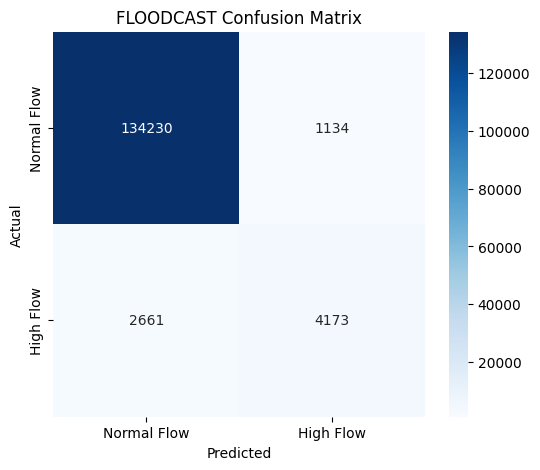

In [42]:
plt.figure(figsize=(6, 5))

cm = confusion_matrix(y_test_cls, y_pred_cls)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Flow", "High Flow"],
    yticklabels=["Normal Flow", "High Flow"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FLOODCAST Confusion Matrix")

plt.show()

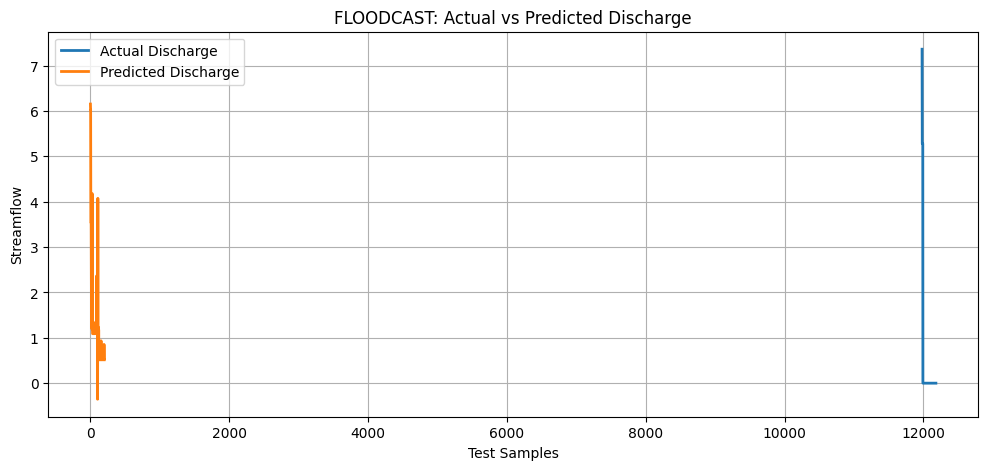

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test_reg.iloc[:200],
    label="Actual Discharge",
    linewidth=2
)

plt.plot(
    y_pred_reg[:200],
    label="Predicted Discharge",
    linewidth=2
)

plt.xlabel("Test Samples")
plt.ylabel("Streamflow")
plt.title("FLOODCAST: Actual vs Predicted Discharge")
plt.legend()
plt.grid(True)

plt.show()

In [44]:
# Save trained models
joblib.dump(discharge_model, "floodcast_discharge_model.pkl")
joblib.dump(highflow_model, "floodcast_highflow_model.pkl")

# Save feature columns
joblib.dump(feature_columns, "floodcast_features.pkl")

# Save high-flow thresholds
joblib.dump(thresholds, "floodcast_thresholds.pkl")

# Save catchment IDs
joblib.dump(selected_catchments, "floodcast_catchments.pkl")

print("FLOODCAST models saved successfully!")
print("\nSaved files:")
print("1. floodcast_discharge_model.pkl")
print("2. floodcast_highflow_model.pkl")
print("3. floodcast_features.pkl")
print("4. floodcast_thresholds.pkl")
print("5. floodcast_catchments.pkl")

FLOODCAST models saved successfully!

Saved files:
1. floodcast_discharge_model.pkl
2. floodcast_highflow_model.pkl
3. floodcast_features.pkl
4. floodcast_thresholds.pkl
5. floodcast_catchments.pkl


In [45]:
def predict_floodcast(input_data):

    input_df = pd.DataFrame([input_data])

    # Ensure correct feature order
    input_df = input_df[feature_columns]

    # Predict next-day discharge
    predicted_discharge = discharge_model.predict(input_df)[0]

    # Predict high-flow probability
    high_flow_probability = highflow_model.predict_proba(input_df)[0][1]

    # Classify flow condition
    if high_flow_probability >= 0.5:
        flow_status = "High Flow"
    else:
        flow_status = "Normal Flow"

    return {
        "Predicted Discharge": round(float(predicted_discharge), 2),
        "High-Flow Probability (%)": round(float(high_flow_probability * 100), 2),
        "Flow Status": flow_status
    }

print("FLOODCAST prediction function created successfully!")

FLOODCAST prediction function created successfully!


In [46]:
# Select one sample from test data
sample_input = X_test.iloc[0].to_dict()

# Generate prediction
prediction = predict_floodcast(sample_input)

print("FLOODCAST TEST PREDICTION")
print("------------------------")

for key, value in prediction.items():
    print(f"{key}: {value}")

FLOODCAST TEST PREDICTION
------------------------
Predicted Discharge: 6.15
High-Flow Probability (%): 0.08
Flow Status: Normal Flow


In [47]:
print("Total catchments:", len(selected_catchments))

print("\nAvailable catchment IDs:")
print(selected_catchments[:20])

print("\nFirst catchment:", selected_catchments[0])

Total catchments: 89

Available catchment IDs:
['10004', '10005', '10008', '10010', '10011', '10013', '10014', '11001', '11005', '11006', '11007', '11010', '12001', '12004', '12006', '12009', '12012', '12015', '12016', '12018']

First catchment: 10004


In [48]:
# Separate dynamic inputs from catchment-specific attributes
static_features = [
    "elev_mean",
    "slope_mean",
    "cwc_area",
    "gauge_elevation",
    "dpsbar"
]

dynamic_features = [
    col for col in feature_columns
    if col not in static_features
]

# Use a real test sample for default input values
sample_input = X_test.iloc[0].to_dict()
default_catchment = str(test_df.iloc[0]["catchment_id"])

# Dashboard prediction function
def dashboard_predict(catchment_id, *values):

    input_data = dict(zip(dynamic_features, values))

    # Get geographical attributes for selected catchment
    catchment_row = topo_selected[
        topo_selected["gauge_id"] == str(catchment_id)
    ].iloc[0]

    for col in static_features:
        input_data[col] = float(catchment_row[col])

    result = predict_floodcast(input_data)

    return (
        f"Predicted Next-Day Discharge: "
        f"{result['Predicted Discharge']}\n\n"
        f"High-Flow Probability: "
        f"{result['High-Flow Probability (%)']}%\n\n"
        f"Flow Status: {result['Flow Status']}"
    )

# Create dashboard
with gr.Blocks(title="FLOODCAST Dashboard") as demo:

    gr.Markdown("# FLOODCAST")
    gr.Markdown(
        "Multi-Catchment River Discharge and High-Flow Prediction System"
    )

    catchment = gr.Dropdown(
        choices=selected_catchments,
        value=default_catchment,
        label="Select Catchment"
    )

    gr.Markdown("### Weather and Historical Flow Inputs")

    dashboard_inputs = []

    for col in dynamic_features:
        dashboard_inputs.append(
            gr.Number(
                label=col,
                value=float(sample_input[col])
            )
        )

    predict_button = gr.Button("Predict")

    output = gr.Textbox(
        label="FLOODCAST Prediction Results",
        lines=5
    )

    predict_button.click(
        fn=dashboard_predict,
        inputs=[catchment] + dashboard_inputs,
        outputs=output
    )

print("FLOODCAST dashboard created successfully!")

demo.launch()

FLOODCAST dashboard created successfully!
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dc9de543da8e014e18.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [49]:
print("FLOODCAST SAMPLE DASHBOARD INPUTS")
print("--------------------------------")

for col in dynamic_features:
    print(f"{col}: {round(float(sample_input[col]), 2)}")


FLOODCAST SAMPLE DASHBOARD INPUTS
--------------------------------
prcp(mm/day): 0.0
tmax(C): 34.76
tmin(C): 18.81
tavg(C): 26.78
srad_lw(w/m2): 403.74
srad_sw(w/m2): 279.9
wind(m/s): 0.59
rel_hum(%): 27.38
pet_gleam(mm/day): 2.44
aet_gleam(mm/day): 1.94
sm_lvl1(kg/m2): 3.0
sm_lvl2(kg/m2): 88.32
sm_lvl3(kg/m2): 177.34
sm_lvl4(kg/m2): 553.48
flow_lag1: 8.46
flow_lag2: 11.62
flow_lag3: 10.75
flow_lag7: 15.95
rain_3day: 0.0
rain_7day: 0.0
flow_mean_7day: 11.46


In [50]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("FLOODCAST THRESHOLD COMPARISON")
print("--------------------------------")

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:

    predictions = (y_prob_cls >= threshold).astype(int)

    precision = precision_score(y_test_cls, predictions)
    recall = recall_score(y_test_cls, predictions)
    f1 = f1_score(y_test_cls, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1-score: {f1:.3f}")


FLOODCAST THRESHOLD COMPARISON
--------------------------------

Threshold: 0.1
Precision: 0.448
Recall: 0.924
F1-score: 0.603

Threshold: 0.2
Precision: 0.570
Recall: 0.849
F1-score: 0.682

Threshold: 0.3
Precision: 0.656
Recall: 0.777
F1-score: 0.711

Threshold: 0.4
Precision: 0.728
Recall: 0.700
F1-score: 0.714

Threshold: 0.5
Precision: 0.786
Recall: 0.611
F1-score: 0.687


In [51]:
# Set the selected threshold
FLOODCAST_THRESHOLD = 0.3

# Update prediction function
def predict_floodcast(input_data):

    input_df = pd.DataFrame([input_data])
    input_df = input_df[feature_columns]

    predicted_discharge = discharge_model.predict(input_df)[0]

    high_flow_probability = highflow_model.predict_proba(input_df)[0][1]

    if high_flow_probability >= FLOODCAST_THRESHOLD:
        flow_status = "HIGH FLOW WARNING"
    else:
        flow_status = "NORMAL FLOW"

    return {
        "Predicted Discharge": round(float(predicted_discharge), 2),
        "High-Flow Probability (%)": round(float(high_flow_probability * 100), 2),
        "Flow Status": flow_status
    }

# Save threshold
joblib.dump(FLOODCAST_THRESHOLD, "floodcast_threshold.pkl")

print("FLOODCAST warning threshold updated!")
print("Selected threshold:", FLOODCAST_THRESHOLD)

FLOODCAST warning threshold updated!
Selected threshold: 0.3


In [52]:
# Stop the previous dashboard
demo.close()

# Rebuild the dashboard using the updated prediction function
with gr.Blocks(title="FLOODCAST Dashboard") as demo:

    gr.Markdown("# FLOODCAST")
    gr.Markdown(
        "Multi-Catchment River Discharge and High-Flow Prediction System"
    )

    catchment = gr.Dropdown(
        choices=selected_catchments,
        value=default_catchment,
        label="Select Catchment"
    )

    gr.Markdown("### Weather and Historical Flow Inputs")

    dashboard_inputs = []

    for col in dynamic_features:
        dashboard_inputs.append(
            gr.Number(
                label=col,
                value=float(sample_input[col])
            )
        )

    predict_button = gr.Button("Predict")

    output = gr.Textbox(
        label="FLOODCAST Prediction Results",
        lines=5
    )

    predict_button.click(
        fn=dashboard_predict,
        inputs=[catchment] + dashboard_inputs,
        outputs=output
    )

demo.launch(share=True, debug=True)

Closing server running on port: 7860
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://72e7db4141467ede6a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://dc9de543da8e014e18.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://72e7db4141467ede6a.gradio.live


In [54]:
print("FLOODCAST HIGH-FLOW TEST")
print("------------------------")

print("\nAccuracy:", accuracy_score(y_test_cls, y_pred_cls))

print("\nClassification Report:")
print(classification_report(y_test_cls, y_pred_cls))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_cls, y_pred_cls))

print("\nROC-AUC Score:", roc_auc_score(y_test_cls, y_prob_cls))

FLOODCAST HIGH-FLOW TEST
------------------------

Accuracy: 0.973311860926314

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99    135364
           1       0.79      0.61      0.69      6834

    accuracy                           0.97    142198
   macro avg       0.88      0.80      0.84    142198
weighted avg       0.97      0.97      0.97    142198


Confusion Matrix:
[[134230   1134]
 [  2661   4173]]

ROC-AUC Score: 0.9821650368271385


In [55]:
# Find test samples with probability >= 30%
high_indices = np.where(y_prob_cls >= 0.3)[0]

print("High-flow samples found:", len(high_indices))

if len(high_indices) > 0:

    sample_index = high_indices[0]

    high_sample = X_test.iloc[sample_index].to_dict()

    result = predict_floodcast(high_sample)

    print("\nFLOODCAST HIGH-FLOW TEST RESULT")
    print("--------------------------------")

    for key, value in result.items():
        print(f"{key}: {value}")

else:
    print("No high-flow samples found.")

High-flow samples found: 8101

FLOODCAST HIGH-FLOW TEST RESULT
--------------------------------
Predicted Discharge: 905.52
High-Flow Probability (%): 81.49
Flow Status: HIGH FLOW WARNING


In [56]:
import os
import joblib

os.makedirs("FLOODCAST_FINAL", exist_ok=True)

joblib.dump(discharge_model, "FLOODCAST_FINAL/discharge_model.pkl")
joblib.dump(highflow_model, "FLOODCAST_FINAL/highflow_model.pkl")
joblib.dump(feature_columns, "FLOODCAST_FINAL/features.pkl")
joblib.dump(thresholds, "FLOODCAST_FINAL/catchment_thresholds.pkl")
joblib.dump(selected_catchments, "FLOODCAST_FINAL/catchments.pkl")
joblib.dump(FLOODCAST_THRESHOLD, "FLOODCAST_FINAL/warning_threshold.pkl")

print("FLOODCAST FINAL MODEL SAVED SUCCESSFULLY!")

print("\nSaved files:")
print(os.listdir("FLOODCAST_FINAL"))

FLOODCAST FINAL MODEL SAVED SUCCESSFULLY!

Saved files:
['warning_threshold.pkl', 'highflow_model.pkl', 'features.pkl', 'discharge_model.pkl', 'catchments.pkl', 'catchment_thresholds.pkl']


In [57]:
import shutil
from google.colab import files

shutil.make_archive(
    "FLOODCAST_FINAL_BACKUP",
    "zip",
    "FLOODCAST_FINAL"
)

print("FLOODCAST backup created successfully!")

files.download("FLOODCAST_FINAL_BACKUP.zip")

FLOODCAST backup created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>